In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

os.listdir('/content/drive/MyDrive')

['Revenue-Figures 2.gsheet',
 'Revenue-Figures 2.xlsx',
 'Excel_RS',
 'cnw-1.docx',
 'Python lab',
 'DS lab',
 'DNV',
 'MathsLab',
 'one.ipynb - auto-6.pdf',
 'Iris (1).xlsx',
 'Colab Notebooks',
 'music.c',
 'CN Module II.gdoc',
 'CN Module III-Part 1.gdoc',
 'CN Module IV- Part 1.gdoc',
 'IPv4,IPv6,NAT- NETWORK  LAYER.gdoc',
 'CN Module I.gdoc',
 'S2MCA',
 'DM Concepts & Techniques _ Han&Kamber (3).gdoc',
 'DM Concepts & Techniques _ Han&Kamber (2).gdoc',
 'DM Concepts & Techniques _ Han&Kamber (1).gdoc',
 'DM Concepts & Techniques _ Han&Kamber.gdoc',
 'DOC-20260126-WA0021.pdf',
 'DOC-20260126-WA0021.gdoc',
 'Docker steps-1.pdf',
 'Docker steps-1.gdoc',
 'S3MCA',
 'ML_Lab',
 'PCOS_Project',
 '03_dataset_audit.ipynb']

In [3]:
import os

project_path = '/content/drive/MyDrive/PCOS_Project'

os.listdir(project_path)


['PCOS_DATASET', 'CLEAN_DATASET', 'SPLIT_DATASET']

In [4]:
dataset_path = '/content/drive/MyDrive/PCOS_Project/CLEAN_DATASET'

os.listdir(dataset_path)

['infected',
 'noninfected',
 'clean_dataset_audit.csv',
 'clean_dataset_phash.csv',
 'strong_near_duplicate_groups.csv']

In [5]:
import os

clean_dataset = "/content/drive/MyDrive/PCOS_Project/CLEAN_DATASET"

clean_infected_path = os.path.join(
    clean_dataset, "infected"
)

clean_noninfected_path = os.path.join(
    clean_dataset, "noninfected"
)

print("Infected folder exists:", os.path.exists(clean_infected_path))
print("Noninfected folder exists:", os.path.exists(clean_noninfected_path))

print("\nImage counts")
print("-" * 40)

infected_count = len(os.listdir(clean_infected_path))
noninfected_count = len(os.listdir(clean_noninfected_path))

print("Infected:", infected_count)
print("Noninfected:", noninfected_count)
print("Total:", infected_count + noninfected_count)

Infected folder exists: True
Noninfected folder exists: True

Image counts
----------------------------------------
Infected: 3150
Noninfected: 778
Total: 3928


#Create CLEAN_DATASET

In [9]:
# ============================================================
# CLEAN DATASET PATHS
# ============================================================

import os

clean_dataset = "/content/drive/MyDrive/PCOS_Project/CLEAN_DATASET"

infected_path = os.path.join(
    clean_dataset, "infected"
)

noninfected_path = os.path.join(
    clean_dataset, "noninfected"
)

print("Infected path:")
print(infected_path)

print("\nNoninfected path:")
print(noninfected_path)

Infected path:
/content/drive/MyDrive/PCOS_Project/CLEAN_DATASET/infected

Noninfected path:
/content/drive/MyDrive/PCOS_Project/CLEAN_DATASET/noninfected


In [10]:
print("\nCLEAN DATASET VERIFICATION")
print("-" * 50)

infected_files = os.listdir(infected_path)
noninfected_files = os.listdir(noninfected_path)

print("Infected images:", len(infected_files))
print("Noninfected images:", len(noninfected_files))
print("Total images:", len(infected_files) + len(noninfected_files))


CLEAN DATASET VERIFICATION
--------------------------------------------------
Infected images: 3150
Noninfected images: 778
Total images: 3928


In [11]:
# ============================================================
# CREATE TRAIN / TEST DATASET STRUCTURE
# ============================================================

import os

# Clean dataset
clean_dataset = "/content/drive/MyDrive/PCOS_Project/CLEAN_DATASET"

# New split dataset
split_dataset = "/content/drive/MyDrive/PCOS_Project/SPLIT_DATASET"

# Create folders
for split in ["train", "test"]:
    for class_name in ["infected", "noninfected"]:
        os.makedirs(
            os.path.join(split_dataset, split, class_name),
            exist_ok=True
        )

print("Train/Test folder structure created successfully.")

Train/Test folder structure created successfully.


In [13]:
# ============================================================
# STEP 2 — GENERATE pHASH FOR CLEAN DATASET
# ============================================================

!pip -q install ImageHash

import os
import pandas as pd
from PIL import Image
import imagehash
from tqdm.auto import tqdm

# Clean dataset paths
clean_dataset = "/content/drive/MyDrive/PCOS_Project/CLEAN_DATASET"

infected_path = os.path.join(
    clean_dataset, "infected"
)

noninfected_path = os.path.join(
    clean_dataset, "noninfected"
)

# Collect clean image paths
image_records = []

for class_name, folder in [
    ("infected", infected_path),
    ("noninfected", noninfected_path)
]:

    for filename in os.listdir(folder):

        filepath = os.path.join(folder, filename)

        if os.path.isfile(filepath):
            image_records.append({
                "path": filepath,
                "filename": filename,
                "class": class_name
            })

print("Images to process:", len(image_records))

# Generate pHash
hash_records = []

for record in tqdm(image_records, desc="Generating pHash"):

    try:
        with Image.open(record["path"]) as img:
            phash = imagehash.phash(img)

        hash_records.append({
            "path": record["path"],
            "filename": record["filename"],
            "class": record["class"],
            "phash": str(phash)
        })

    except Exception as e:
        print("Error:", record["filename"], e)

# Convert to DataFrame
phash_df = pd.DataFrame(hash_records)

print("\nSuccessfully generated pHash for:",
      len(phash_df), "images")

# Save checkpoint
phash_csv = os.path.join(
    clean_dataset,
    "clean_dataset_phash.csv"
)

phash_df.to_csv(phash_csv, index=False)

print("pHash checkpoint saved to:")
print(phash_csv)

Images to process: 3928


Generating pHash:   0%|          | 0/3928 [00:00<?, ?it/s]


Successfully generated pHash for: 3928 images
pHash checkpoint saved to:
/content/drive/MyDrive/PCOS_Project/CLEAN_DATASET/clean_dataset_phash.csv


In [15]:
# ============================================================
# STEP 3 — FIND VISUALLY SIMILAR IMAGE GROUPS
# ============================================================

import os
import pandas as pd
from collections import defaultdict

# Load saved pHash checkpoint
phash_csv = "/content/drive/MyDrive/PCOS_Project/CLEAN_DATASET/clean_dataset_phash.csv"

phash_df = pd.read_csv(phash_csv)

print("pHash records loaded:", len(phash_df))


# ------------------------------------------------------------
# Create groups using pHash distance <= 4
# ------------------------------------------------------------

# Convert hexadecimal pHash strings back to ImageHash objects
hashes = {
    row["path"]: imagehash.hex_to_hash(row["phash"])
    for _, row in phash_df.iterrows()
}

paths = list(hashes.keys())

# Union-Find structure for grouping similar images
parent = {path: path for path in paths}


def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x


def union(a, b):
    root_a = find(a)
    root_b = find(b)

    if root_a != root_b:
        parent[root_b] = root_a


# Compare images within the same class
for class_name in ["infected", "noninfected"]:

    class_paths = phash_df[
        phash_df["class"] == class_name
    ]["path"].tolist()

    print(f"\nProcessing {class_name}: {len(class_paths)} images")

    for i in range(len(class_paths)):

        for j in range(i + 1, len(class_paths)):

            p1 = class_paths[i]
            p2 = class_paths[j]

            distance = hashes[p1] - hashes[p2]

            if distance <= 4:
                union(p1, p2)


# ------------------------------------------------------------
# Build groups
# ------------------------------------------------------------

groups = defaultdict(list)

for path in paths:
    groups[find(path)].append(path)

# Keep only groups containing more than one image
similarity_groups = [
    group for group in groups.values()
    if len(group) > 1
]

print("\n" + "=" * 60)
print("VISUAL SIMILARITY GROUP ANALYSIS")
print("=" * 60)

print("Total images:", len(paths))
print("Similarity groups:", len(similarity_groups))
print(
    "Images involved:",
    sum(len(group) for group in similarity_groups)
)

print(
    "Largest group:",
    max(len(group) for group in similarity_groups)
    if similarity_groups else 0
)

pHash records loaded: 3928

Processing infected: 3150 images

Processing noninfected: 778 images

VISUAL SIMILARITY GROUP ANALYSIS
Total images: 3928
Similarity groups: 381
Images involved: 1986
Largest group: 247


In [16]:
# ============================================================
# STEP 4 — SIMILARITY GROUP SIZE DISTRIBUTION
# ============================================================

from collections import Counter

group_sizes = [len(group) for group in similarity_groups]

distribution = Counter(group_sizes)

print("Similarity Group Size Distribution")
print("-" * 50)

for size, count in sorted(distribution.items()):
    print(f"{count} groups contain {size} images")

print("\nSummary")
print("-" * 50)
print("Total similarity groups:", len(similarity_groups))
print("Images in similarity groups:", sum(group_sizes))
print("Largest similarity group:", max(group_sizes))

Similarity Group Size Distribution
--------------------------------------------------
249 groups contain 2 images
41 groups contain 3 images
35 groups contain 4 images
11 groups contain 5 images
7 groups contain 6 images
3 groups contain 7 images
4 groups contain 8 images
2 groups contain 9 images
5 groups contain 10 images
2 groups contain 11 images
2 groups contain 12 images
3 groups contain 13 images
2 groups contain 14 images
1 groups contain 15 images
1 groups contain 16 images
2 groups contain 19 images
1 groups contain 20 images
2 groups contain 22 images
1 groups contain 24 images
1 groups contain 26 images
1 groups contain 28 images
1 groups contain 40 images
1 groups contain 54 images
1 groups contain 131 images
1 groups contain 211 images
1 groups contain 247 images

Summary
--------------------------------------------------
Total similarity groups: 381
Images in similarity groups: 1986
Largest similarity group: 247


In [17]:
# ============================================================
# STEP 5 — BUILD STRONG NEAR-DUPLICATE GROUPS
# pHash distance = 0 AND SSIM >= 0.95
# ============================================================

import os
import cv2
import numpy as np
from collections import defaultdict
from skimage.metrics import structural_similarity as ssim

# ------------------------------------------------------------
# Load pHash data
# ------------------------------------------------------------

phash_csv = "/content/drive/MyDrive/PCOS_Project/CLEAN_DATASET/clean_dataset_phash.csv"

phash_df = pd.read_csv(phash_csv)

# Convert pHash strings to ImageHash objects
hashes = {
    row["path"]: imagehash.hex_to_hash(row["phash"])
    for _, row in phash_df.iterrows()
}

# ------------------------------------------------------------
# Union-Find structure
# ------------------------------------------------------------

parent = {path: path for path in hashes}


def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x


def union(a, b):
    root_a = find(a)
    root_b = find(b)

    if root_a != root_b:
        parent[root_b] = root_a


# ------------------------------------------------------------
# Compare only same-class pHash-0 pairs
# ------------------------------------------------------------

strong_pairs = []

for class_name in ["infected", "noninfected"]:

    class_paths = phash_df[
        phash_df["class"] == class_name
    ]["path"].tolist()

    print(f"Checking {class_name}: {len(class_paths)} images")

    for i in range(len(class_paths)):

        for j in range(i + 1, len(class_paths)):

            p1 = class_paths[i]
            p2 = class_paths[j]

            # First filter: pHash distance must be 0
            if hashes[p1] - hashes[p2] != 0:
                continue

            # Read grayscale images
            img1 = cv2.imread(p1, cv2.IMREAD_GRAYSCALE)
            img2 = cv2.imread(p2, cv2.IMREAD_GRAYSCALE)

            if img1 is None or img2 is None:
                continue

            # Resize to common dimensions
            img1 = cv2.resize(img1, (224, 224))
            img2 = cv2.resize(img2, (224, 224))

            score = ssim(img1, img2)

            if score >= 0.95:

                strong_pairs.append({
                    "class": class_name,
                    "image1": p1,
                    "image2": p2,
                    "ssim": score
                })

                union(p1, p2)


print("\n" + "=" * 60)
print("STRONG NEAR-DUPLICATE ANALYSIS")
print("=" * 60)

print("Strong pairs (pHash 0 + SSIM >= 0.95):",
      len(strong_pairs))


# ------------------------------------------------------------
# Build groups
# ------------------------------------------------------------

strong_groups_dict = defaultdict(list)

for path in hashes:
    root = find(path)
    strong_groups_dict[root].append(path)

strong_groups = [
    group
    for group in strong_groups_dict.values()
    if len(group) > 1
]

print("Strong near-duplicate groups:",
      len(strong_groups))

print("Images involved:",
      sum(len(g) for g in strong_groups))

print("Largest group:",
      max([len(g) for g in strong_groups])
      if strong_groups else 0)

Checking infected: 3150 images
Checking noninfected: 778 images

STRONG NEAR-DUPLICATE ANALYSIS
Strong pairs (pHash 0 + SSIM >= 0.95): 90
Strong near-duplicate groups: 88
Images involved: 177
Largest group: 3


In [18]:
# ============================================================
# SAVE STRONG NEAR-DUPLICATE GROUP INFORMATION
# ============================================================

import pandas as pd
import os

group_records = []

for group_id, group in enumerate(strong_groups, start=1):

    for path in group:

        row = phash_df[phash_df["path"] == path].iloc[0]

        group_records.append({
            "group_id": group_id,
            "path": path,
            "filename": row["filename"],
            "class": row["class"],
            "group_size": len(group)
        })

strong_groups_df = pd.DataFrame(group_records)

output_file = os.path.join(
    clean_dataset,
    "strong_near_duplicate_groups.csv"
)

strong_groups_df.to_csv(output_file, index=False)

print("Checkpoint saved successfully!")
print(output_file)
print("Rows saved:", len(strong_groups_df))

Checkpoint saved successfully!
/content/drive/MyDrive/PCOS_Project/CLEAN_DATASET/strong_near_duplicate_groups.csv
Rows saved: 177


In [20]:
# ============================================================
# STEP 6 — CREATE LEAKAGE-AWARE 80:20 TRAIN/TEST SPLIT
# ============================================================

import os
import shutil
import random
import pandas as pd
from collections import defaultdict

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

clean_dataset = "/content/drive/MyDrive/PCOS_Project/CLEAN_DATASET"

infected_path = os.path.join(
    clean_dataset, "infected"
)

noninfected_path = os.path.join(
    clean_dataset, "noninfected"
)

split_dataset = "/content/drive/MyDrive/PCOS_Project/SPLIT_DATASET"


# ------------------------------------------------------------
# Recreate the strong near-duplicate groups
# ------------------------------------------------------------

group_csv = os.path.join(
    clean_dataset,
    "strong_near_duplicate_groups.csv"
)

strong_groups_df = pd.read_csv(group_csv)

print("Strong near-duplicate records loaded:",
      len(strong_groups_df))


# ------------------------------------------------------------
# Create groups
# ------------------------------------------------------------

groups = defaultdict(list)

for _, row in strong_groups_df.iterrows():
    groups[row["group_id"]].append(row["path"])


# ------------------------------------------------------------
# Collect all images by class
# ------------------------------------------------------------

all_images = {
    "infected": [
        os.path.join(infected_path, f)
        for f in os.listdir(infected_path)
        if os.path.isfile(os.path.join(infected_path, f))
    ],

    "noninfected": [
        os.path.join(noninfected_path, f)
        for f in os.listdir(noninfected_path)
        if os.path.isfile(os.path.join(noninfected_path, f))
    ]
}


# ------------------------------------------------------------
# Create group units
#
# Images in a strong near-duplicate group stay together.
# Images not belonging to a group are treated individually.
# ------------------------------------------------------------

group_units = {
    "infected": [],
    "noninfected": []
}

grouped_paths = set()

for group_id, paths in groups.items():

    classes = set(
        strong_groups_df[
            strong_groups_df["group_id"] == group_id
        ]["class"]
    )

    # Strong groups should be same-class
    for class_name in classes:
        group_units[class_name].append(paths)

    grouped_paths.update(paths)


# Add singleton images
for class_name in ["infected", "noninfected"]:

    for path in all_images[class_name]:

        if path not in grouped_paths:
            group_units[class_name].append([path])


# ------------------------------------------------------------
# Shuffle groups reproducibly
# ------------------------------------------------------------

random.seed(42)

for class_name in group_units:
    random.shuffle(group_units[class_name])


# ------------------------------------------------------------
# Select approximately 20% of each class for TEST
# without breaking groups
# ------------------------------------------------------------

train_paths = {
    "infected": [],
    "noninfected": []
}

test_paths = {
    "infected": [],
    "noninfected": []
}


for class_name in ["infected", "noninfected"]:

    total = len(all_images[class_name])
    target_test = round(total * 0.20)

    current_test = 0

    for unit in group_units[class_name]:

        # Add this group to test if it doesn't make
        # the test set excessively larger than the target.
        if current_test < target_test:

            test_paths[class_name].extend(unit)
            current_test += len(unit)

        else:
            train_paths[class_name].extend(unit)


print("\nTARGET / ACTUAL SPLIT")
print("=" * 60)

for class_name in ["infected", "noninfected"]:

    print(f"\n{class_name}")

    print("Total:", len(all_images[class_name]))
    print("Train:", len(train_paths[class_name]))
    print("Test :", len(test_paths[class_name]))

    print(
        "Test percentage:",
        round(
            len(test_paths[class_name])
            / len(all_images[class_name]) * 100,
            2
        ),
        "%"
    )


# ------------------------------------------------------------
# Create output folders
# ------------------------------------------------------------

for split in ["train", "test"]:

    for class_name in ["infected", "noninfected"]:

        os.makedirs(
            os.path.join(
                split_dataset,
                split,
                class_name
            ),
            exist_ok=True
        )


# ------------------------------------------------------------
# Copy images
# ------------------------------------------------------------

def copy_images(paths, destination):

    for path in paths:

        filename = os.path.basename(path)

        shutil.copy2(
            path,
            os.path.join(destination, filename)
        )


print("\nCopying images...")


for class_name in ["infected", "noninfected"]:

    copy_images(
        train_paths[class_name],
        os.path.join(
            split_dataset,
            "train",
            class_name
        )
    )

    copy_images(
        test_paths[class_name],
        os.path.join(
            split_dataset,
            "test",
            class_name
        )
    )


print("\n" + "=" * 60)
print("80:20 SPLIT CREATED SUCCESSFULLY")
print("=" * 60)

print("Train total:",
      len(train_paths["infected"]) +
      len(train_paths["noninfected"]))

print("Test total:",
      len(test_paths["infected"]) +
      len(test_paths["noninfected"]))

print("Overall total:",
      len(train_paths["infected"]) +
      len(train_paths["noninfected"]) +
      len(test_paths["infected"]) +
      len(test_paths["noninfected"]))

Strong near-duplicate records loaded: 177

TARGET / ACTUAL SPLIT

infected
Total: 3150
Train: 2520
Test : 630
Test percentage: 20.0 %

noninfected
Total: 778
Train: 622
Test : 156
Test percentage: 20.05 %

Copying images...

80:20 SPLIT CREATED SUCCESSFULLY
Train total: 3142
Test total: 786
Overall total: 3928


In [6]:
# ============================================================
# STEP 7.1 — IMPORT LIBRARIES
# ============================================================

import os
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

print("PyTorch version:", torch.__version__)

PyTorch version: 2.11.0+cu128


In [7]:
# ============================================================
# STEP 7.2 — DEFINE TRAIN AND TEST PATHS
# ============================================================

split_dataset = "/content/drive/MyDrive/PCOS_Project/SPLIT_DATASET"

train_dir = os.path.join(split_dataset, "train")
test_dir = os.path.join(split_dataset, "test")

print("Train directory:")
print(train_dir)

print("\nTest directory:")
print(test_dir)

print("\nTrain classes:")
print(os.listdir(train_dir))

print("\nTest classes:")
print(os.listdir(test_dir))

Train directory:
/content/drive/MyDrive/PCOS_Project/SPLIT_DATASET/train

Test directory:
/content/drive/MyDrive/PCOS_Project/SPLIT_DATASET/test

Train classes:
['infected', 'noninfected']

Test classes:
['infected', 'noninfected']


In [9]:
# ============================================================
# UPDATED STEP 7.3 — IMAGE PREPROCESSING & AUGMENTATION
# ============================================================

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    # Mild augmentation
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(
        degrees=5,
        fill=0
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


test_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Updated training transformations:")
print(train_transform)

print("\nTesting transformations:")
print(test_transform)

Updated training transformations:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-5.0, 5.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.85, 1.15), contrast=(0.85, 1.15), saturation=None, hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Testing transformations:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [10]:
# ============================================================
# STEP 7.4 — CREATE PYTORCH DATASETS
# ============================================================

from torchvision import datasets

# Create training dataset
train_dataset = datasets.ImageFolder(
    root=train_dir,
    transform=train_transform
)

# Create testing dataset
test_dataset = datasets.ImageFolder(
    root=test_dir,
    transform=test_transform
)

print("Datasets recreated successfully!")
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

Datasets recreated successfully!
Training images: 3142
Testing images: 786


In [11]:
# ============================================================
# STEP 7.5 — CREATE DATALOADERS
# ============================================================

from torch.utils.data import DataLoader

# Batch size
BATCH_SIZE = 32

# Training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

# Testing DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

print("DataLoaders recreated successfully!")
print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

DataLoaders recreated successfully!
Training batches: 99
Testing batches: 25


In [12]:
# ============================================================
# STEP 7.6 — INSPECT ONE DATA BATCH
# ============================================================

# Get one batch from the training DataLoader
images, labels = next(iter(train_loader))

print("Batch inspection")
print("-" * 40)

print("Image tensor shape:", images.shape)
print("Label tensor shape:", labels.shape)

print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)

print("\nUnique labels in batch:", labels.unique().tolist())

print("\nMinimum pixel value:", images.min().item())
print("Maximum pixel value:", images.max().item())

Batch inspection
----------------------------------------
Image tensor shape: torch.Size([32, 3, 224, 224])
Label tensor shape: torch.Size([32])
Image data type: torch.float32
Label data type: torch.int64

Unique labels in batch: [0, 1]

Minimum pixel value: -2.1179039478302
Maximum pixel value: 2.640000104904175


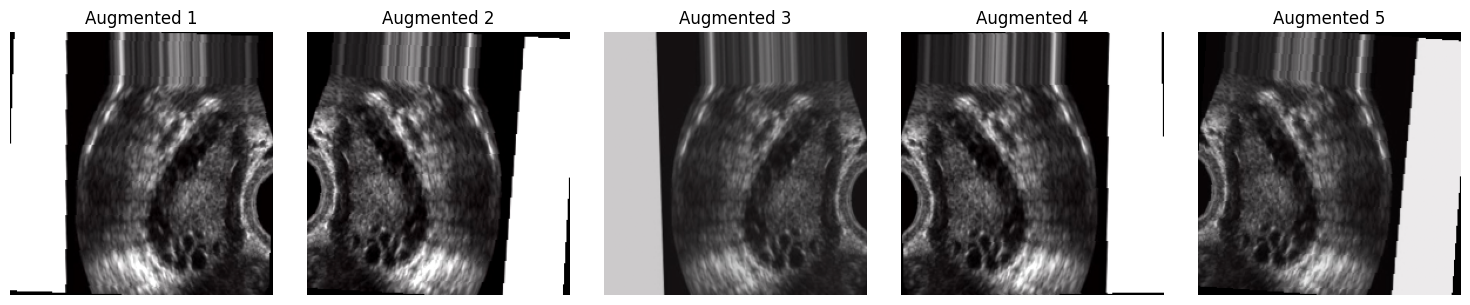

Original class label: 0
Class: infected


In [13]:
# ============================================================
# STEP 7.7 — VISUALIZE TRAINING AUGMENTATION
# ============================================================

import matplotlib.pyplot as plt

# Get one original image path
sample_path, sample_label = train_dataset.samples[0]

# Load the original image
from PIL import Image

original_image = Image.open(sample_path).convert("RGB")

# Apply the training transformation multiple times
augmented_images = [
    train_transform(original_image)
    for _ in range(5)
]


# ------------------------------------------------------------
# Function to reverse ImageNet normalization
# for visualization
# ------------------------------------------------------------

def denormalize(tensor):

    mean = torch.tensor(
        [0.485, 0.456, 0.406]
    ).view(3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225]
    ).view(3, 1, 1)

    image = tensor * std + mean

    return image.clamp(0, 1)


# ------------------------------------------------------------
# Display augmented images
# ------------------------------------------------------------

plt.figure(figsize=(15, 3))

for i, image_tensor in enumerate(augmented_images):

    image = denormalize(image_tensor)

    image = image.permute(1, 2, 0).numpy()

    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"Augmented {i+1}")

plt.tight_layout()
plt.show()

print("Original class label:", sample_label)
print("Class:", train_dataset.classes[sample_label])

In [14]:

images, labels = next(iter(train_loader))

print("Final preprocessing verification")
print("-" * 40)
print("Batch shape:", images.shape)
print("Labels shape:", labels.shape)
print("Data type:", images.dtype)
print("Labels:", labels.unique().tolist())

Final preprocessing verification
----------------------------------------
Batch shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
Data type: torch.float32
Labels: [0, 1]


##Algorithm 1 - ResNet50 training

In [15]:
import torch
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [16]:
#Load pretrained ResNet50
from torchvision import models

# Load pretrained ResNet50
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)

print(model)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 199MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [17]:
#Modify ResNet50 for our 2-class problem
import torch.nn as nn

# Get the number of input features to the final layer
num_features = model.fc.in_features

# Replace the original 1000-class layer with a 2-class layer
model.fc = nn.Linear(num_features, 2)

# Move model to GPU
model = model.to(device)

print(model.fc)
print("Model device:", next(model.parameters()).device)

Linear(in_features=2048, out_features=2, bias=True)
Model device: cuda:0


### Transfer Learning and Fine-Tuning

The pretrained ResNet50 model is used as the starting point instead of training the network from scratch. The pretrained layers have already learned general visual features from ImageNet.

In this project, all ResNet50 layers are kept trainable so that the model can fine-tune these learned features for PCOS ultrasound image classification. The newly replaced fully connected layer is also trained to classify the images into the two target classes: infected and noninfected.

Thus, the model uses previously learned visual knowledge while adapting its parameters to the characteristics of our PCOS ultrasound dataset.

In [18]:
#Choose the transfer-learning strategy
# Check which parameters are trainable
trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

total_params = sum(p.numel() for p in model.parameters())

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 23512130
Trainable parameters: 23512130


In [19]:
import torch.nn as nn

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)


In [20]:
#Training the ResNet50
num_epochs = 5

for epoch in range(num_epochs):

    # Training mode
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        # Move data to GPU
        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backward pass
        loss.backward()

        # Update model weights
        optimizer.step()

        # Track loss
        running_loss += loss.item()

        # Track accuracy
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

Epoch [1/5] Loss: 0.1644 Accuracy: 93.83%
Epoch [2/5] Loss: 0.0262 Accuracy: 99.33%
Epoch [3/5] Loss: 0.0237 Accuracy: 99.33%
Epoch [4/5] Loss: 0.0184 Accuracy: 99.43%
Epoch [5/5] Loss: 0.0243 Accuracy: 99.33%


##Evaluate ResNet50 on the test set

In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)
import numpy as np
import torch

model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        # Predicted class
        _, predicted = torch.max(outputs, 1)

        # Probability of class 1 (noninfected)
        probabilities = torch.softmax(outputs, dim=1)[:, 1]

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

# Convert to NumPy arrays
all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

# Calculate metrics
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(all_labels, all_predictions, zero_division=0)
recall = recall_score(all_labels, all_predictions, zero_division=0)
f1 = f1_score(all_labels, all_predictions, zero_division=0)
auc = roc_auc_score(all_labels, all_probabilities)

print("ResNet50 Test Results")
print("=" * 40)
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {auc:.4f}")

print("\nClassification Report")
print("=" * 40)
print(classification_report(
    all_labels,
    all_predictions,
    target_names=test_dataset.classes,
    zero_division=0
))

print("\nConfusion Matrix")
print("=" * 40)
print(confusion_matrix(all_labels, all_predictions))

ResNet50 Test Results
Accuracy : 0.9885
Precision: 0.9682
Recall   : 0.9744
F1-score : 0.9712
ROC-AUC  : 0.9967

Classification Report
              precision    recall  f1-score   support

    infected       0.99      0.99      0.99       630
 noninfected       0.97      0.97      0.97       156

    accuracy                           0.99       786
   macro avg       0.98      0.98      0.98       786
weighted avg       0.99      0.99      0.99       786


Confusion Matrix
[[625   5]
 [  4 152]]


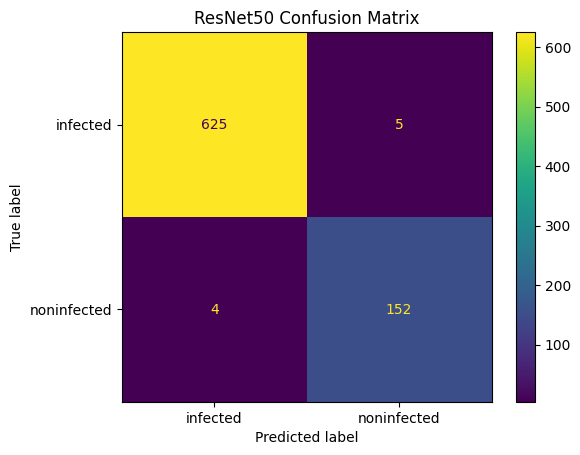

In [22]:
#Confusion Matrix Visualization
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=test_dataset.classes
)

disp.plot()
plt.title("ResNet50 Confusion Matrix")
plt.show()

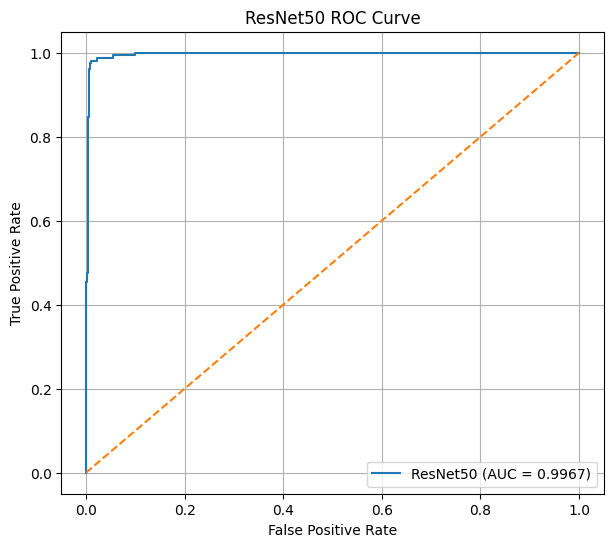

In [23]:
#ROC Curve
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# ROC curve
fpr, tpr, thresholds = roc_curve(
    all_labels,
    all_probabilities
)

auc_score = roc_auc_score(
    all_labels,
    all_probabilities
)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"ResNet50 (AUC = {auc_score:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ResNet50 ROC Curve")
plt.legend()
plt.grid()
plt.show()

##Handle the class imbalance

In [24]:
#Class-weighted ResNet50
# Calculate class weights from the training set

import torch

class_counts = torch.bincount(
    torch.tensor(train_dataset.targets)
)

weights = len(train_dataset) / (2 * class_counts.float())

print("Class mapping:", train_dataset.class_to_idx)
print("Class counts:", class_counts.tolist())
print("Class weights:", weights.tolist())

Class mapping: {'infected': 0, 'noninfected': 1}
Class counts: [2520, 622]
Class weights: [0.6234127283096313, 2.525723457336426]


In [25]:
#Train the class-weighted ResNet50
import torch
import torch.nn as nn
from torchvision import models

# Load a fresh pretrained ResNet50
weighted_model = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

# Replace final layer for 2-class classification
num_features = weighted_model.fc.in_features
weighted_model.fc = nn.Linear(num_features, 2)

# Move model to GPU
weighted_model = weighted_model.to(device)

# Class-weighted loss
class_weights = torch.tensor(
    [0.6234127283, 2.5257234573],
    dtype=torch.float32
).to(device)

weighted_criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# Optimizer
weighted_optimizer = torch.optim.Adam(
    weighted_model.parameters(),
    lr=0.0001
)

print("Class weights:", class_weights)
print("Loss function:", weighted_criterion)
print("Optimizer:", weighted_optimizer)
print("Model device:", next(weighted_model.parameters()).device)

Class weights: tensor([0.6234, 2.5257], device='cuda:0')
Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0
)
Model device: cuda:0


In [26]:
# ============================================================
# STEP 8.10 — TRAIN CLASS-WEIGHTED RESNET50
# ============================================================

num_epochs = 5

for epoch in range(num_epochs):

    weighted_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        # Move data to GPU
        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        weighted_optimizer.zero_grad()

        # Forward pass
        outputs = weighted_model(images)

        # Calculate weighted loss
        loss = weighted_criterion(outputs, labels)

        # Backward pass
        loss.backward()

        # Update model weights
        weighted_optimizer.step()

        # Track loss
        running_loss += loss.item()

        # Track accuracy
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )

Epoch [1/5] Loss: 0.1777 Accuracy: 93.25%
Epoch [2/5] Loss: 0.0359 Accuracy: 99.30%
Epoch [3/5] Loss: 0.0300 Accuracy: 99.27%
Epoch [4/5] Loss: 0.0300 Accuracy: 99.01%
Epoch [5/5] Loss: 0.0278 Accuracy: 99.36%


In [27]:
# ============================================================
# STEP 8.11 — EVALUATE CLASS-WEIGHTED RESNET50
# ============================================================

weighted_model.eval()

weighted_labels = []
weighted_predictions = []
weighted_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = weighted_model(images)

        # Predicted class
        _, predicted = torch.max(outputs, 1)

        # Probability of class 1 (noninfected)
        probabilities = torch.softmax(outputs, dim=1)[:, 1]

        weighted_labels.extend(labels.cpu().numpy())
        weighted_predictions.extend(predicted.cpu().numpy())
        weighted_probabilities.extend(probabilities.cpu().numpy())

# Convert to NumPy
weighted_labels = np.array(weighted_labels)
weighted_predictions = np.array(weighted_predictions)
weighted_probabilities = np.array(weighted_probabilities)

# Calculate metrics
weighted_accuracy = accuracy_score(
    weighted_labels,
    weighted_predictions
)

weighted_precision = precision_score(
    weighted_labels,
    weighted_predictions,
    zero_division=0
)

weighted_recall = recall_score(
    weighted_labels,
    weighted_predictions,
    zero_division=0
)

weighted_f1 = f1_score(
    weighted_labels,
    weighted_predictions,
    zero_division=0
)

weighted_auc = roc_auc_score(
    weighted_labels,
    weighted_probabilities
)

print("Class-Weighted ResNet50 Test Results")
print("=" * 45)

print(f"Accuracy : {weighted_accuracy:.4f}")
print(f"Precision: {weighted_precision:.4f}")
print(f"Recall   : {weighted_recall:.4f}")
print(f"F1-score : {weighted_f1:.4f}")
print(f"ROC-AUC  : {weighted_auc:.4f}")

print("\nClassification Report")
print("=" * 45)

print(classification_report(
    weighted_labels,
    weighted_predictions,
    target_names=test_dataset.classes,
    zero_division=0
))

print("\nConfusion Matrix")
print("=" * 45)

print(
    confusion_matrix(
        weighted_labels,
        weighted_predictions
    )
)

Class-Weighted ResNet50 Test Results
Accuracy : 0.9885
Precision: 0.9682
Recall   : 0.9744
F1-score : 0.9712
ROC-AUC  : 0.9972

Classification Report
              precision    recall  f1-score   support

    infected       0.99      0.99      0.99       630
 noninfected       0.97      0.97      0.97       156

    accuracy                           0.99       786
   macro avg       0.98      0.98      0.98       786
weighted avg       0.99      0.99      0.99       786


Confusion Matrix
[[625   5]
 [  4 152]]


In [28]:
# ============================================================
# STEP 8.12 — STORE RESNET50 RESULTS
# ============================================================

resnet_results = {
    "ResNet50 Baseline": {
        "Accuracy": 0.9885,
        "Precision": 0.9682,
        "Recall": 0.9744,
        "F1-score": 0.9712,
        "ROC-AUC": 0.9967
    },

    "ResNet50 Class-Weighted": {
        "Accuracy": 0.9885,
        "Precision": 0.9682,
        "Recall": 0.9744,
        "F1-score": 0.9712,
        "ROC-AUC": 0.9972
    }
}

print("ResNet50 experiments stored successfully.")
print(resnet_results)

ResNet50 experiments stored successfully.
{'ResNet50 Baseline': {'Accuracy': 0.9885, 'Precision': 0.9682, 'Recall': 0.9744, 'F1-score': 0.9712, 'ROC-AUC': 0.9967}, 'ResNet50 Class-Weighted': {'Accuracy': 0.9885, 'Precision': 0.9682, 'Recall': 0.9744, 'F1-score': 0.9712, 'ROC-AUC': 0.9972}}
